In [1]:
'''
Projeto de IA (N2) - Recomendação musical por agregação de vizinhança aprendida
Integrantes: Arthur Jones Bicalho dos Santos 10420317;
             Luis Felipe Santos do Nascimento 10420572
Síntese: rodada final no teste (baselines e GraphSAGE com 3 sementes), tabela principal, bootstrap pareado e figuras.
Histórico:
2026-11-10 | Arthur | Criação do notebook
2026-11-13 | Luis Felipe | Célula de localização da raiz do projeto, sementes em processos paralelos (CPU), exemplo de pesos aprendidos e NDCG por quartil
2026-11-18 | Luis Felipe | Atualização da lista de integrantes
'''

'\nProjeto de IA (N2) - Recomendação musical por agregação de vizinhança aprendida\nIntegrantes: Arthur Jones Bicalho dos Santos 10420317;\n             Luis Felipe Santos do Nascimento 10420572\nSíntese: rodada final no teste (baselines e GraphSAGE com 3 sementes), tabela principal, bootstrap pareado e figuras.\nHistórico:\n2026-11-10 | Arthur | Criação do notebook\n2026-11-13 | Luis Felipe | Célula de localização da raiz do projeto, sementes em processos paralelos (CPU), exemplo de pesos aprendidos e NDCG por quartil\n'

In [2]:
# Localiza a raiz do repositório (pasta que contém src/) e passa a trabalhar a partir dela.
# Sem isto, abrir o notebook dentro de notebooks/ quebra os imports de src e os caminhos
# relativos data/ e results/ (FileNotFoundError).
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'data.py').exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.makedirs('results', exist_ok=True)
print('Raiz do projeto:', ROOT)

Raiz do projeto: projeto_ia


In [3]:
import numpy as np, pandas as pd
from src.data import load_processed
from src.baselines import popularity_fn
from src.metrics import evaluate
from src.experiments import seed_job, run_parallel

D = load_processed()
SEEDS, Ks = (0, 1, 2), (10, 50)
# hiperparâmetros escolhidos na validação (notebook 02)
grade = pd.read_csv('results/sensibilidade_hiperparametros.csv').sort_values('val_ndcg10', ascending=False)
BEST_T, BEST_D, BEST_LR = int(grade.iloc[0]['T']), int(grade.iloc[0]['d']), float(grade.iloc[0]['lr'])
als = pd.read_csv('results/sensibilidade_als.csv').sort_values('val_ndcg10', ascending=False).iloc[0]
BEST_ALS = dict(factors=int(als['factors']), reg=float(als['reg']), alpha=float(als['alpha']))
MAX_EPOCHS = 100                                       # com early stopping (paciência de 3 avaliações)
print('GraphSAGE:', dict(T=BEST_T, d=BEST_D, lr=BEST_LR), '| ALS:', BEST_ALS)

test_mask = (D['train_csr'] + D['val_csr']).tocsr()   # no teste, treino e validação já são conhecidos
target = D['test_csr']
rows, per_user, rec_store = [], {}, {}

# popularidade é determinística: roda uma vez
s, pu, rc = evaluate(popularity_fn(D['train_csr']), test_mask, target, Ks)
rows.append({'modelo': 'Popularidade', 'seed': 0, 'segundos_treino': 0.0, **s})
per_user[('Popularidade', 0)] = pu; rec_store[('Popularidade', 0)] = rc

# modelos estocásticos: uma semente por processo (a semente também muda as caminhadas aleatórias)
jobs = [dict(seed=sd, Ks=Ks, T=BEST_T, d=BEST_D, lr=BEST_LR, max_epochs=MAX_EPOCHS, als=BEST_ALS, threads=2)
        for sd in SEEDS]
for sd, (r, pu, rc, curvas) in zip(SEEDS, run_parallel(seed_job, jobs, workers=len(SEEDS))):
    rows += r; per_user.update(pu); rec_store.update(rc)
    for lw, h in curvas.items():
        h.to_csv(f'results/curva_treino_{lw}_seed{sd}.csv', index=False)
        if sd == 0:
            h.to_csv(f'results/curva_treino_{lw}.csv', index=False)

res = pd.DataFrame(rows)
res.to_csv('results/resultados_por_seed.csv', index=False)
res

~/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GraphSAGE: {'T': 20, 'd': 32, 'lr': 0.01} | ALS: {'factors': 128, 'reg': 0.01, 'alpha': 1.0}


,modelo,seed,segundos_treino,prec@10,rec@10,ndcg@10,pop@10,cov@10,prec@50,rec@50,ndcg@50,pop@50,cov@50
0,Popularidade,0,0.000000,0.017438,0.039619,0.034114,7.795408,0.002118,0.010451,0.118314,0.061019,7.357049,0.006440
1,Caminhada (Pixie),0,1.918701,0.015133,0.034759,0.027335,6.864884,0.678783,0.007486,0.086777,0.045562,5.915190,0.997119
2,ALS,0,19.817978,0.070218,0.162896,0.145240,6.110703,0.169632,0.030892,0.359213,0.213310,5.806619,0.341383
3,GraphSAGE (pesos fixos),0,1226.176487,0.048288,0.112136,0.091532,5.748846,0.555753,0.026274,0.306266,0.158346,5.546855,0.872564
4,GraphSAGE (pesos aprendidos),0,3030.696093,0.049270,0.114546,0.094530,6.022698,0.446958,0.026033,0.303079,0.159468,5.766945,0.786562
5,Caminhada (Pixie),1,2.041355,0.014995,0.034638,0.026956,6.867552,0.668192,0.007515,0.087008,0.045318,5.915906,0.996950
6,ALS,1,20.889056,0.069557,0.161372,0.144274,6.109540,0.169209,0.030925,0.359757,0.213144,5.805652,0.341891
7,GraphSAGE (pesos fixos),1,1217.434811,0.050837,0.118323,0.096759,5.703963,0.603288,0.026800,0.312839,0.163756,5.528955,0.892815
8,GraphSAGE (pesos aprendidos),1,3879.872898,0.049239,0.115119,0.093839,5.660111,0.602271,0.026268,0.306740,0.159778,5.517998,0.898577
9,Caminhada (Pixie),2,1.879497,0.015336,0.035253,0.028091,6.868134,0.669463,0.007542,0.087196,0.046221,5.913593,0.996187


In [4]:
# tabela principal
cols = ['prec@10', 'rec@10', 'ndcg@10', 'cov@10', 'pop@10', 'ndcg@50', 'cov@50']
g = res.groupby('modelo')[cols]
tabela = g.mean().round(4).astype(str) + ' ± ' + g.std(ddof=0).fillna(0).round(4).astype(str)
tabela['segundos_treino'] = res.groupby('modelo')['segundos_treino'].mean().round(0)
tabela.to_csv('results/tabela_principal.csv')
print(tabela.to_markdown())

| modelo                       | prec@10         | rec@10          | ndcg@10         | cov@10          | pop@10          | ndcg@50         | cov@50          |   segundos_treino |
|:-----------------------------|:----------------|:----------------|:----------------|:----------------|:----------------|:----------------|:----------------|------------------:|
| ALS                          | 0.0699 ± 0.0003 | 0.1621 ± 0.0006 | 0.1449 ± 0.0004 | 0.1694 ± 0.0002 | 6.1095 ± 0.001  | 0.2135 ± 0.0004 | 0.3417 ± 0.0002 |                20 |
| Caminhada (Pixie)            | 0.0152 ± 0.0001 | 0.0349 ± 0.0003 | 0.0275 ± 0.0005 | 0.6721 ± 0.0047 | 6.8669 ± 0.0014 | 0.0457 ± 0.0004 | 0.9968 ± 0.0004 |                 2 |
| GraphSAGE (pesos aprendidos) | 0.0496 ± 0.0005 | 0.1157 ± 0.0013 | 0.0949 ± 0.001  | 0.5354 ± 0.0652 | 5.7941 ± 0.1625 | 0.1608 ± 0.0017 | 0.851 ± 0.0473  |              3607 |
| GraphSAGE (pesos fixos)      | 0.0492 ± 0.0011 | 0.1144 ± 0.0028 | 0.0934 ± 0.0024 | 0.5613 ± 0.0323 | 

In [5]:
# bootstrap pareado entre usuários: GraphSAGE com pesos aprendidos contra cada referência.
# Cada usuário entra com a média da métrica nas 3 sementes, para que a comparação não dependa de uma semente só.
def media_usuario(modelo, met):
    return np.mean([v[met] for (m, _), v in per_user.items() if m == modelo], axis=0)

def ic_bootstrap(a, b, n=1000, seed=0):
    rng = np.random.default_rng(seed); d = a - b
    m = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)]
    return d.mean(), np.percentile(m, [2.5, 97.5])

boot = []
for met in ('ndcg@10', 'rec@10', 'pop@10'):
    a = media_usuario('GraphSAGE (pesos aprendidos)', met)
    for ref in ('GraphSAGE (pesos fixos)', 'Caminhada (Pixie)', 'ALS', 'Popularidade'):
        diff, ci = ic_bootstrap(a, media_usuario(ref, met))
        boot.append(dict(metrica=met, referencia=ref, diferenca=diff, ic95_inf=ci[0], ic95_sup=ci[1]))
        print(f'{met} vs {ref}: {diff:+.4f}  IC95% [{ci[0]:+.4f}, {ci[1]:+.4f}]')
pd.DataFrame(boot).to_csv('results/bootstrap_pareado.csv', index=False)

# a mesma diferença (pesos aprendidos - pesos fixos) semente a semente
por_seed = []
for sd in SEEDS:
    for met in ('ndcg@10', 'pop@10', 'cov@10'):
        if met == 'cov@10':
            r = res[res['seed'] == sd].set_index('modelo')[met]
            por_seed.append(dict(seed=sd, metrica=met, diferenca=r['GraphSAGE (pesos aprendidos)'] - r['GraphSAGE (pesos fixos)']))
            continue
        diff, ci = ic_bootstrap(per_user[('GraphSAGE (pesos aprendidos)', sd)][met], per_user[('GraphSAGE (pesos fixos)', sd)][met])
        por_seed.append(dict(seed=sd, metrica=met, diferenca=diff, ic95_inf=ci[0], ic95_sup=ci[1]))
por_seed = pd.DataFrame(por_seed); por_seed.to_csv('results/aprendidos_vs_fixos_por_seed.csv', index=False)
por_seed.round(4)

ndcg@10 vs GraphSAGE (pesos fixos): +0.0015  IC95% [+0.0002, +0.0026]


ndcg@10 vs Caminhada (Pixie): +0.0674  IC95% [+0.0659, +0.0690]


ndcg@10 vs ALS: -0.0501  IC95% [-0.0521, -0.0477]


ndcg@10 vs Popularidade: +0.0607  IC95% [+0.0589, +0.0626]


rec@10 vs GraphSAGE (pesos fixos): +0.0013  IC95% [-0.0002, +0.0026]


rec@10 vs Caminhada (Pixie): +0.0808  IC95% [+0.0791, +0.0826]


... (3 outputs left out)

pop@10 vs Caminhada (Pixie): -1.0728  IC95% [-1.0854, -1.0601]


pop@10 vs ALS: -0.3154  IC95% [-0.3248, -0.3062]


pop@10 vs Popularidade: -2.0013  IC95% [-2.0149, -1.9884]


,seed,metrica,diferenca,ic95_inf,ic95_sup
0,0,ndcg@10,0.0030,0.0010,0.0050
1,0,pop@10,0.2739,0.2633,0.2843
2,0,cov@10,-0.1088,NaN,NaN
3,1,ndcg@10,-0.0029,-0.0049,-0.0008
4,1,pop@10,-0.0439,-0.0554,-0.0333
5,1,cov@10,-0.0010,NaN,NaN
6,2,ndcg@10,0.0043,0.0022,0.0063
7,2,pop@10,-0.1599,-0.1708,-0.1479
8,2,cov@10,0.0321,NaN,NaN


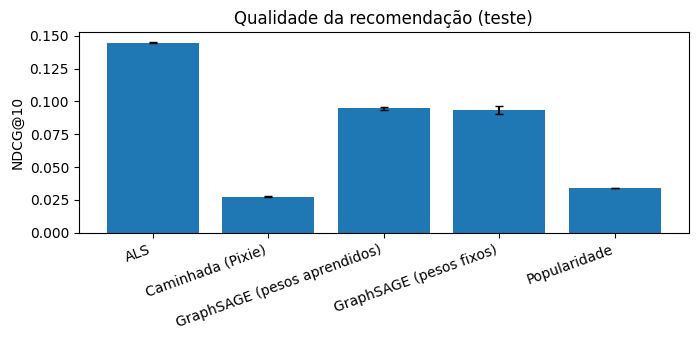

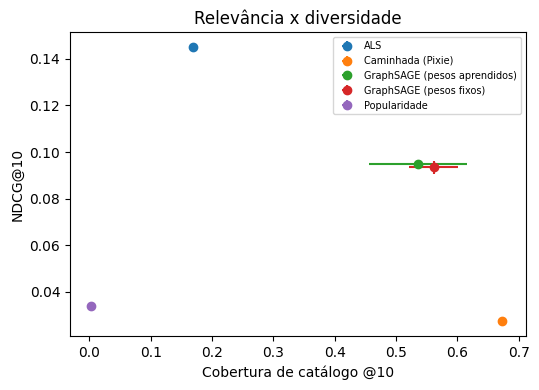

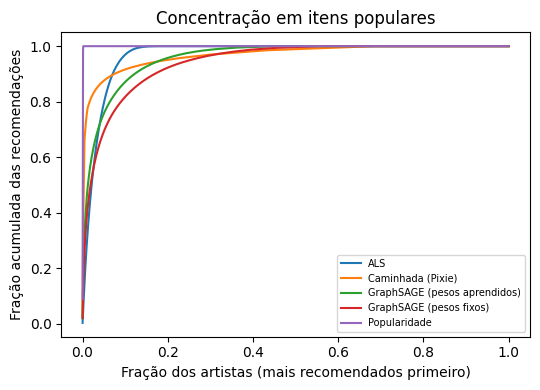

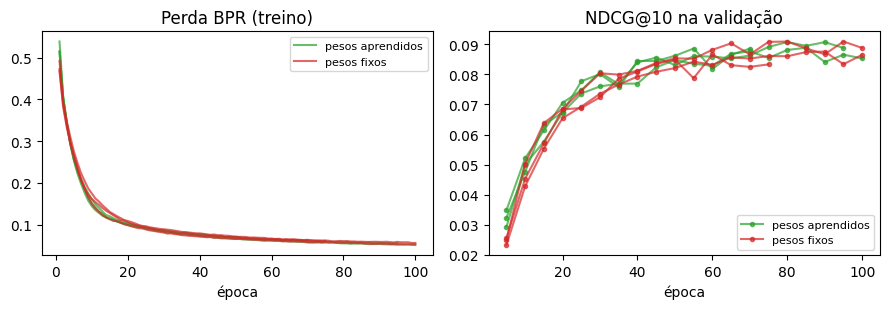

In [6]:
# graficos
import matplotlib.pyplot as plt
g2 = res.groupby('modelo')[cols].agg(['mean', 'std']).fillna(0)
ordem = list(g2.index)

# Fig. 1: qualidade (NDCG@10)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(ordem, g2[('ndcg@10', 'mean')], yerr=g2[('ndcg@10', 'std')], capsize=3)
ax.set(ylabel='NDCG@10', title='Qualidade da recomendação (teste)')
plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.savefig('results/fig1_ndcg.png', dpi=200)

# Fig. 2: relevância x diversidade
fig, ax = plt.subplots(figsize=(5.5, 4))
for m in ordem:
    ax.errorbar(g2.loc[m, ('cov@10', 'mean')], g2.loc[m, ('ndcg@10', 'mean')],
                xerr=g2.loc[m, ('cov@10', 'std')], yerr=g2.loc[m, ('ndcg@10', 'std')], fmt='o', label=m)
ax.set(xlabel='Cobertura de catálogo @10', ylabel='NDCG@10', title='Relevância x diversidade')
ax.legend(fontsize=7); plt.tight_layout(); plt.savefig('results/fig2_relevancia_diversidade.png', dpi=200)

# Fig. 3: concentração das recomendações em poucos artistas
fig, ax = plt.subplots(figsize=(5.5, 4))
for m in ordem:
    rc = np.sort(rec_store[(m, 0)][10])[::-1]
    ax.plot(np.arange(1, len(rc) + 1) / len(rc), rc.cumsum() / rc.sum(), label=m)
ax.set(xlabel='Fração dos artistas (mais recomendados primeiro)',
       ylabel='Fração acumulada das recomendações', title='Concentração em itens populares')
ax.legend(fontsize=7); plt.tight_layout(); plt.savefig('results/fig3_concentracao.png', dpi=200)

# Fig. 4: curvas de treino das duas variantes do GraphSAGE (3 sementes cada)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for lw, cor, nome in ((True, 'tab:green', 'pesos aprendidos'), (False, 'tab:red', 'pesos fixos')):
    for sd in SEEDS:
        h = pd.read_csv(f'results/curva_treino_{lw}_seed{sd}.csv'); v = h.dropna(subset=['val_ndcg@10'])
        ax[0].plot(h['epoch'], h['loss'], color=cor, alpha=.7, label=nome if sd == 0 else None)
        ax[1].plot(v['epoch'], v['val_ndcg@10'], marker='o', ms=3, color=cor, alpha=.7, label=nome if sd == 0 else None)
ax[0].set(title='Perda BPR (treino)', xlabel='época'); ax[0].legend(fontsize=8)
ax[1].set(title='NDCG@10 na validação', xlabel='época'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('results/fig4_treino.png', dpi=200)


In [7]:
# NDCG@10 por quartil de atividade do usuário (média das 3 sementes)
act = np.asarray(D['train_csr'].sum(1)).ravel()
q = pd.qcut(act, 4, labels=['Q1 (menos ativos)', 'Q2', 'Q3', 'Q4 (mais ativos)'])
seg = pd.DataFrame({m: pd.Series(media_usuario(m, 'ndcg@10')).groupby(q, observed=True).mean() for m in ordem})
seg.to_csv('results/ndcg_por_quartil.csv'); seg.round(4)

,ALS,Caminhada (Pixie),GraphSAGE (pesos aprendidos),GraphSAGE (pesos fixos),Popularidade
Q1 (menos ativos),0.1143,0.0200,0.0791,0.0754,0.0197
Q2,0.1444,0.0269,0.0927,0.0910,0.0338
Q3,0.1666,0.0329,0.1073,0.1078,0.0438
Q4 (mais ativos),0.1670,0.0334,0.1081,0.1084,0.0448


## Interpretabilidade: pesos aprendidos x contagens normalizadas
Carrega a variante com pesos aprendidos (semente 0) e compara, para alguns usuários, o peso `alpha` que a primeira camada atribui a cada vizinho com a contagem de visitas normalizada usada na variante de pesos fixos.

In [8]:
import torch
from torch_geometric.utils import softmax
from src.data import PROC
from src.walks import build_adj, random_walk_counts, walk_graph
from src.model import RecGNN

torch.set_num_threads(4)
indptr, indices = build_adj(D['train'], D['nU'], D['nA'])
C = random_walk_counts(indptr, indices, seed=0)
ei, ew = walk_graph(C, BEST_T)
# modelo de pesos aprendidos da semente 0, salvo pela rodada final (mesmas caminhadas: seed=0)
m = RecGNN(D['nU'], D['nA'], D['country'], D['n_country'], BEST_D, 2, True)
m.load_state_dict(torch.load('results/cache/modelo_seed0_aprendidoTrue.pt')); m.eval()

# nomes dos artistas na mesma ordem do índice 'a' (ordem alfabética usada em index_and_features)
inter = pd.read_parquet(PROC / 'interactions.parquet', columns=['artist', 'a'])
nomes = inter.drop_duplicates('a').set_index('a')['artist'].sort_index().values

with torch.no_grad():
    conv = m.convs[0]; x = m.emb.weight + m.cty(m.c_idx); src, dst = ei
    s = conv.score(torch.cat([x[dst], x[src], ew.unsqueeze(-1)], dim=-1)).squeeze(-1)
    alpha = softmax(s, dst, num_nodes=x.size(0))
pesos = pd.DataFrame({'centro': dst.numpy(), 'vizinho': src.numpy(), 'contagem_norm': ew.numpy(), 'alpha': alpha.numpy()})
pesos['tipo_vizinho'] = np.where(pesos['vizinho'] >= D['nU'], 'artista', 'usuário')
pesos['nome_vizinho'] = [nomes[v - D['nU']] if v >= D['nU'] else f'usuário {v}' for v in pesos['vizinho']]
u = pesos[pesos['centro'] < D['nU']]
print('Correlação de Spearman entre alpha e contagem normalizada (centros = usuários):',
      round(u[['contagem_norm', 'alpha']].corr(method='spearman').iloc[0, 1], 3))
print('Soma de alpha por tipo de vizinho (média por usuário):')
print((u.groupby('tipo_vizinho')['alpha'].sum() / D['nU']).round(3))
print('Soma da contagem normalizada por tipo de vizinho (média por usuário):')
print((u.groupby('tipo_vizinho')['contagem_norm'].sum() / D['nU']).round(3))
ex = pd.concat([pesos[pesos['centro'] == uid].nlargest(5, 'alpha') for uid in (0, 1)])
ex.to_csv('results/exemplo_pesos_alpha.csv', index=False)
ex[['centro', 'nome_vizinho', 'tipo_vizinho', 'contagem_norm', 'alpha']].round(3)

Correlação de Spearman entre alpha e contagem normalizada (centros = usuários): 0.256
Soma de alpha por tipo de vizinho (média por usuário):
tipo_vizinho
artista    0.939
usuário    0.061
Name: alpha, dtype: float32
Soma da contagem normalizada por tipo de vizinho (média por usuário):
tipo_vizinho
artista    0.89
usuário    0.11
Name: contagem_norm, dtype: float32


,centro,nome_vizinho,tipo_vizinho,contagem_norm,alpha
5,0,goldfrapp,artista,0.062,0.095
6,0,rob zombie,artista,0.062,0.072
3,0,juliette & the licks,artista,0.062,0.066
8,0,jack off jill,artista,0.042,0.061
7,0,schandmaul,artista,0.062,0.057
37,1,cocorosie,artista,0.029,0.098
34,1,spazz,artista,0.043,0.065
26,1,usuário 17359,usuário,0.043,0.061
30,1,doom,artista,0.043,0.060
20,1,scholastic deth,artista,0.116,0.060
